# Week 4 – Washington D.C. Bike Sharing Digital Twin

**Team B | Replay-mode synchronization | K = 0.5**

This notebook adapts the Seoul Bike Sharing approach to the uploaded `washington_bikedataset.csv` (Kaggle Bike Sharing Demand). It uses hourly rental counts, time of day, temperature, humidity and wind speed. **Rainfall is excluded** because this dataset does not contain rainfall in millimetres. `workingday` is **not** treated as service availability.

Replay sequence: **Observe → Synchronize → Predict next hour → Validate → Repeat**. The prediction is saved before the next observed rental count is read. The next-hour weather is approximated using the **current-hour weather** (persistence assumption), so future measured weather is not leaked into forecasts.

## 1. Imports and load observations

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('washington_bikedataset.csv')
if not csv_path.exists():
    csv_path = Path('../washington_bikedataset.csv')
if not csv_path.exists():
    csv_path = Path('/mnt/data/washington_bikedataset.csv')

raw = pd.read_csv(csv_path)
print('Source columns:', raw.columns.tolist())

required = ['datetime', 'count', 'temp', 'humidity', 'windspeed']
missing_columns = [c for c in required if c not in raw.columns]
if missing_columns:
    raise ValueError(f'Missing required columns: {missing_columns}')

df = raw[required].rename(columns={
    'datetime': 'Timestamp',
    'count': 'Rented Bike Count',
    'temp': 'Temperature',
    'humidity': 'Humidity',
    'windspeed': 'Wind Speed'
}).copy()
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
print('Rows loaded:', len(df))

Source columns: ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']
Rows loaded: 10886


## 2. Data quality and chronological ordering

The Kaggle `train.csv` dataset covers only part of each month; gaps between observations are handled explicitly during replay.

In [2]:
print('Missing values by column:')
print(df.isna().sum())
print('Duplicate timestamps:', df['Timestamp'].duplicated().sum())
print('Invalid rental counts:', (df['Rented Bike Count'] < 0).sum())
print('Invalid humidity:', (~df['Humidity'].between(0, 100)).sum())
print('Invalid wind speed:', (df['Wind Speed'] < 0).sum())

df = df.dropna().drop_duplicates('Timestamp')
df = df[(df['Rented Bike Count'] >= 0) &
        df['Humidity'].between(0, 100) &
        (df['Wind Speed'] >= 0)].copy()
df = df.sort_values('Timestamp').reset_index(drop=True)
df['Month'] = df['Timestamp'].dt.month
df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.date
df['YearMonth'] = df['Timestamp'].dt.to_period('M')

print('Clean rows:', len(df))
print('Start:', df['Timestamp'].min(), '| End:', df['Timestamp'].max())
print('Chronologically sorted:', df['Timestamp'].is_monotonic_increasing)
print('Nonconsecutive hour pairs:', int((df['Timestamp'].diff().dropna() != pd.Timedelta(hours=1)).sum()))

Missing values by column:
Timestamp            0
Rented Bike Count    0
Temperature          0
Humidity             0
Wind Speed           0
dtype: int64
Duplicate timestamps: 0
Invalid rental counts: 0
Invalid humidity: 0
Invalid wind speed: 0
Clean rows: 10886
Start: 2011-01-01 00:00:00 | End: 2012-12-19 23:00:00
Chronologically sorted: True
Nonconsecutive hour pairs: 65


## 3. Plot historical observations

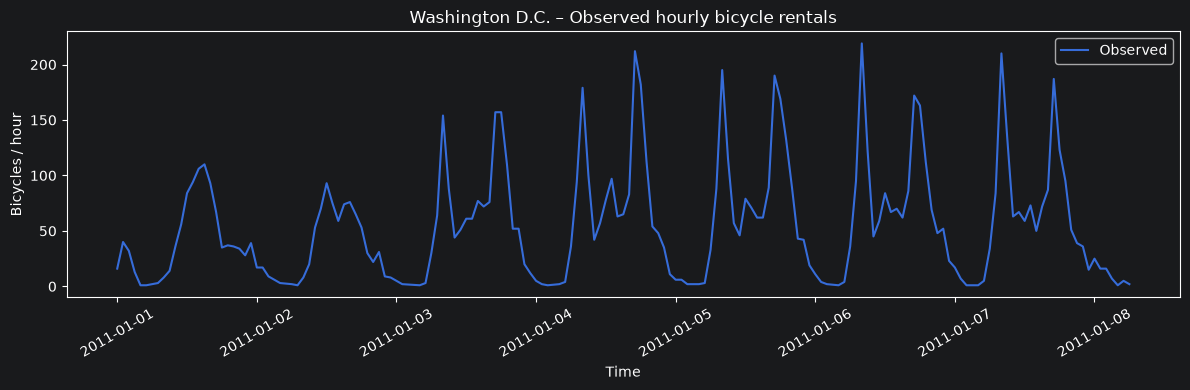

In [3]:
sample = df.head(168)
plt.figure(figsize=(12, 4))
plt.plot(sample['Timestamp'], sample['Rented Bike Count'], label='Observed')
plt.title('Washington D.C. – Observed hourly bicycle rentals')
plt.xlabel('Time'); plt.ylabel('Bicycles / hour')
plt.xticks(rotation=30); plt.legend(); plt.tight_layout(); plt.show()

## 4. Split by whole days within each year-month

The first approximately 80% of **days in each individual year-month** are used for training; the remaining days for evaluation. The split is chronological within each month, but this is **not** an unseen-future-year evaluation.

In [4]:
train_parts, test_parts = [], []
for period, group in df.groupby('YearMonth'):
    days = sorted(group['Day'].unique())
    cutoff = int(len(days) * 0.8)
    train_parts.append(group[group['Day'].isin(days[:cutoff])])
    test_parts.append(group[group['Day'].isin(days[cutoff:])])

train = pd.concat(train_parts).sort_values('Timestamp').copy()
test = pd.concat(test_parts).sort_values('Timestamp').copy()
print('Training rows:', len(train), '| Test rows:', len(test))
print('Training and test timestamps overlap:', bool(set(train['Timestamp']) & set(test['Timestamp'])))

Training rows: 8600 | Test rows: 2286
Training and test timestamps overlap: False


## 5. Week 3 baseline: month-hour average × weather effects

Only training data is used to fit the historical averages and weather multipliers. This is the same modelling approach as Seoul, with **three weather variables instead of four**.

In [5]:
weather = ['Temperature', 'Humidity', 'Wind Speed']
rental_average = train.groupby(['Month', 'Hour'])['Rented Bike Count'].mean()
monthly_weather = train.groupby('Month')[weather].mean()

active = train.copy()
active['Baseline'] = [rental_average.loc[m, h] for m, h in zip(active['Month'], active['Hour'])]
active = active[active['Baseline'] > 0].copy()
active['Relative Rentals'] = active['Rented Bike Count'] / active['Baseline']

weather_effects = {}
for column in weather:
    above = active[column] >= active['Month'].map(monthly_weather[column])
    averages = active.groupby(['Month', above])['Relative Rentals'].mean()
    for month in monthly_weather.index:
        for is_above in [False, True]:
            weather_effects[(month, column, is_above)] = averages.get((month, is_above), 1.0)

print('Monthly-hourly baselines:', len(rental_average))
print('Weather effect entries:', len(weather_effects))

Monthly-hourly baselines: 288
Weather effect entries: 72


## 6. Original static simulation

Internal estimates are floating point; nonnegative clamping is applied when necessary, and rounding is reserved for reporting.

In [6]:
def simulate(row):
    month, hour = row['Month'], row['Hour']
    estimate = float(rental_average.loc[month, hour])
    for column in weather:
        is_above = row[column] >= monthly_weather.loc[month, column]
        estimate *= weather_effects[(month, column, is_above)]
    return max(0.0, estimate)

test['Week 3 baseline'] = test.apply(simulate, axis=1)
print(test[['Timestamp', 'Rented Bike Count', 'Week 3 baseline']].head(8).to_string(index=False))

          Timestamp  Rented Bike Count  Week 3 baseline
2011-01-16 00:00:00                 39        31.806587
2011-01-16 01:00:00                 23        23.228047
2011-01-16 02:00:00                 16        18.522365
2011-01-16 03:00:00                 15         8.799606
2011-01-16 04:00:00                  1         4.497012
2011-01-16 05:00:00                  2        11.331865
2011-01-16 06:00:00                  1        45.356281
2011-01-16 07:00:00                  3       114.269520


## 7. Week 4: synchronization and chronological replay

At hour $t$:

- $D_{updated}(t)=D_{sim}(t)+0.5[D_{obs}(t)-D_{sim}(t)]$
- $\Delta D(t)=S(t+1 \mid \text{current weather})-S(t)$
- $D_{pred}(t+1)=\max(0,D_{updated}(t)+\Delta D(t))$

`S` is the Week 3 baseline. To avoid future-weather leakage, the **current** weather is reused when estimating the next-hour baseline. Only the next hour's calendar month and hour are advanced. The prediction is stored before the loop proceeds to read the next observed rental count.

When timestamps are not consecutive, the state is restarted. No service shutdown field is available; this example models completed rentals as a proxy for demand.

In [7]:
K = 0.5

def synchronize(simulated, observed):
    return simulated + K * (observed - simulated)

def run_twin(data):
    rows = data.sort_values('Timestamp').to_dict('records')
    results = []
    pending_prediction = None
    previous_time = None

    for i, current in enumerate(rows):
        timestamp = current['Timestamp']
        consecutive = (previous_time is not None and
                       timestamp - previous_time == pd.Timedelta(hours=1))

        # A prediction for this hour must already exist before reading its observation.
        if not consecutive:
            pending_prediction = None
        simulated = simulate(current) if pending_prediction is None else pending_prediction
        static_baseline = simulate(current)

        # Observe the CURRENT hour and synchronize the current state.
        observed = current['Rented Bike Count']
        updated = synchronize(simulated, observed)

        # Validate the prediction that was saved at the PREVIOUS hour.
        if consecutive:
            results.append({
                'Timestamp': timestamp,
                'Observed': float(observed),
                'Simulated': float(simulated),
                'Synchronized': float(updated),
                'Week 3 baseline': float(static_baseline),
                'Week 4 prediction': float(simulated)
            })

        # Predict the NEXT hour using only current weather and known calendar time.
        pending_prediction = None
        if i + 1 < len(rows):
            next_time = rows[i + 1]['Timestamp']  # timestamp only, not its measured values
            if next_time - timestamp == pd.Timedelta(hours=1):
                next_input = current.copy()
                next_input['Timestamp'] = next_time
                next_input['Month'] = next_time.month
                next_input['Hour'] = next_time.hour
                delta = simulate(next_input) - static_baseline
                pending_prediction = max(0.0, updated + delta)

        previous_time = timestamp

    return pd.DataFrame(results)

results = run_twin(test)
print('Evaluated one-hour-ahead predictions:', len(results))
print(results.head(10).to_string(index=False))

Evaluated one-hour-ahead predictions: 2255
          Timestamp  Observed  Simulated  Synchronized  Week 3 baseline  Week 4 prediction
2011-01-16 01:00:00      23.0  26.824754     24.912377        23.228047          26.824754
2011-01-16 02:00:00      16.0  20.206695     18.103347        18.522365          20.206695
2011-01-16 03:00:00      15.0  13.407201     14.203600         8.799606          13.407201
2011-01-16 04:00:00       1.0   8.266088      4.633044         4.497012           8.266088
2011-01-16 05:00:00       2.0  11.467896      6.733948        11.331865          11.467896
2011-01-16 06:00:00       1.0  40.758365     20.879182        45.356281          40.758365
2011-01-16 07:00:00       3.0  98.306006     50.653003       114.269520          98.306006
2011-01-16 08:00:00      18.0 184.124388    101.062194       156.102398         184.124388
2011-01-16 09:00:00      32.0  38.399374     35.199687        93.439578          38.399374
2011-01-16 10:00:00      79.0   3.339422     41

## 8. Plot 1 – Observed vs simulated vs synchronized

The synchronized line uses the **current observation**. This plot illustrates state correction; it is **not** an independent forecast evaluation.

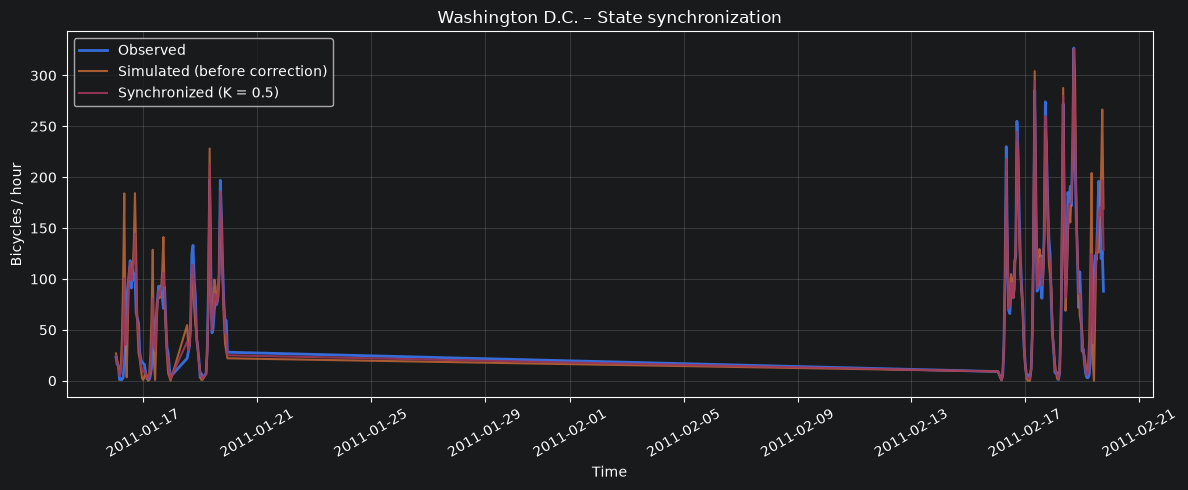

In [8]:
week = results.head(168)
plt.figure(figsize=(12, 5))
plt.plot(week['Timestamp'], week['Observed'], label='Observed', linewidth=2)
plt.plot(week['Timestamp'], week['Simulated'], label='Simulated (before correction)', alpha=0.8)
plt.plot(week['Timestamp'], week['Synchronized'], label='Synchronized (K = 0.5)', alpha=0.9)
plt.title('Washington D.C. – State synchronization')
plt.xlabel('Time'); plt.ylabel('Bicycles / hour')
plt.xticks(rotation=30); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

## 9. Plot 2 – One-hour-ahead prediction vs observation

All three curves are aligned at the **target hour**. The Week 4 prediction was made and saved one hour earlier.

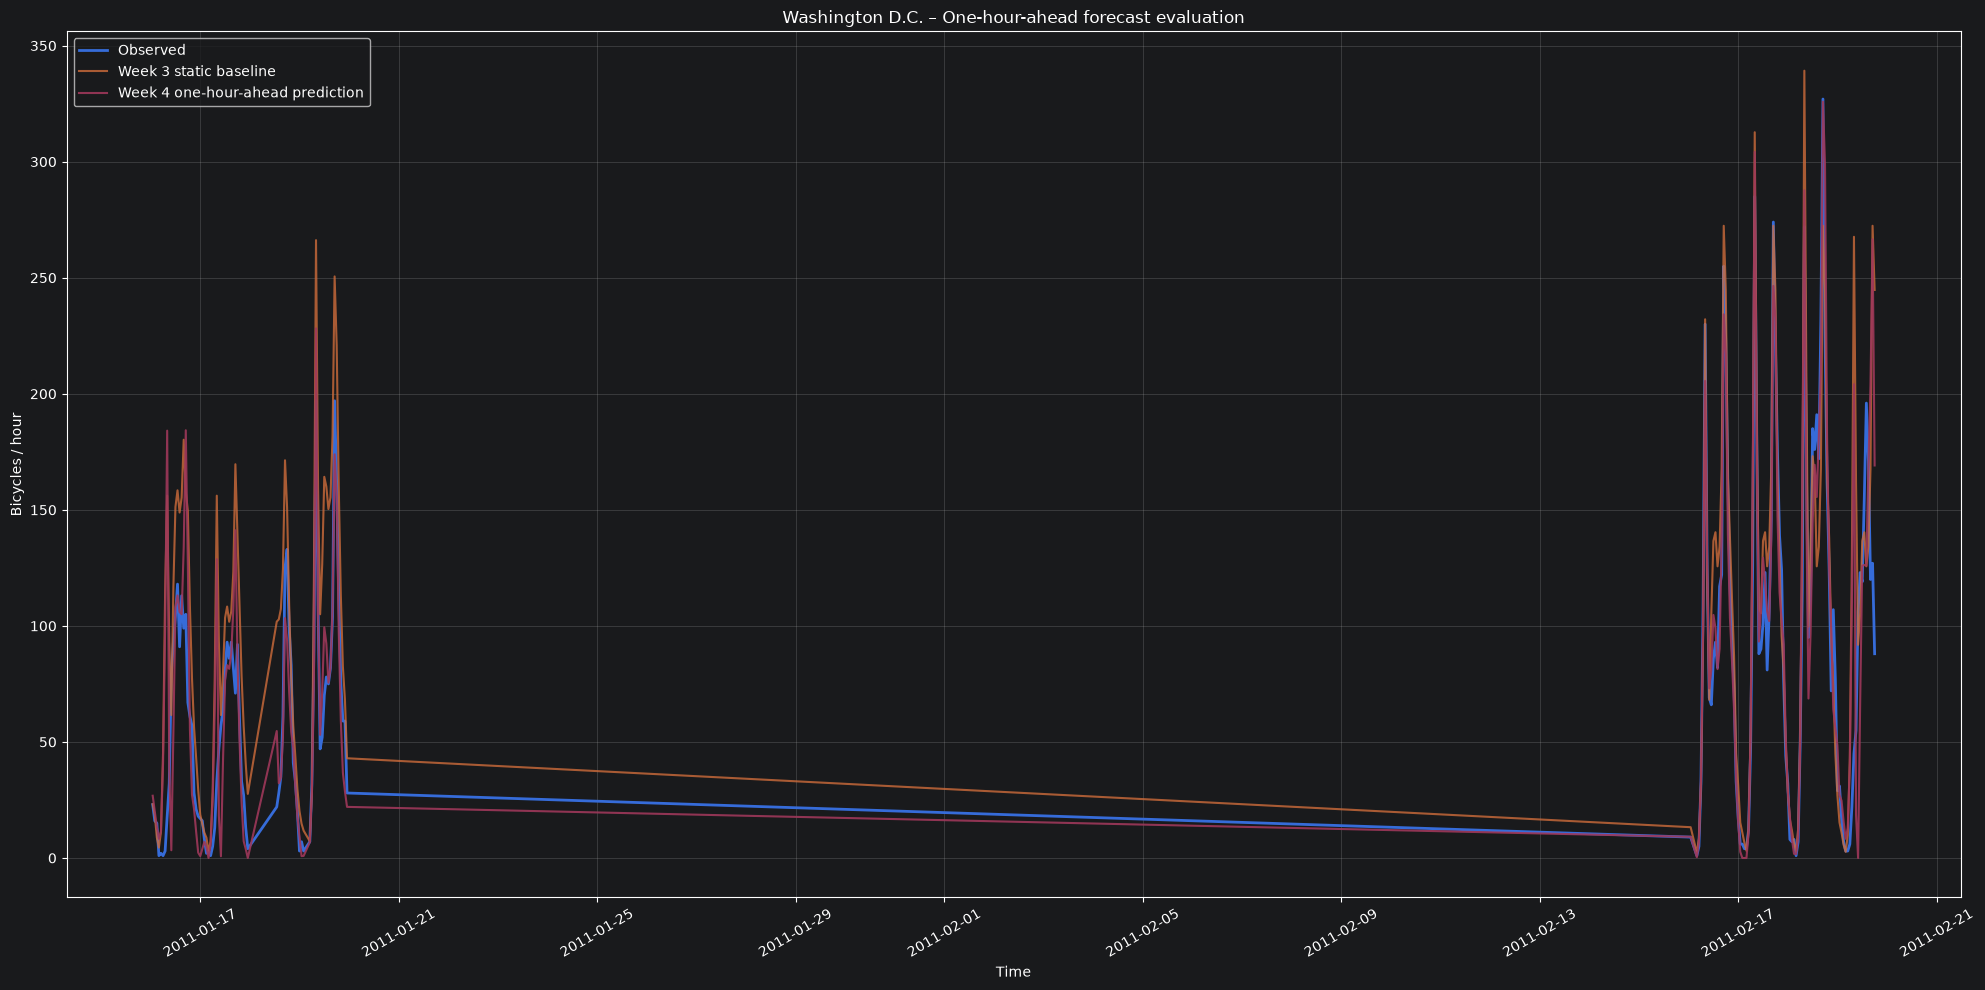

In [20]:
plt.figure(figsize=(20, 10))
plt.plot(week['Timestamp'], week['Observed'], label='Observed', linewidth=2)
plt.plot(week['Timestamp'], week['Week 3 baseline'], label='Week 3 static baseline', alpha=0.8)
plt.plot(week['Timestamp'], week['Week 4 prediction'], label='Week 4 one-hour-ahead prediction', alpha=0.9)
plt.title('Washington D.C. – One-hour-ahead forecast evaluation')
plt.xlabel('Time'); plt.ylabel('Bicycles / hour')
plt.xticks(rotation=30); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

## 10. MAE on identical evaluation hours

Do not interpret the synchronized-state error as forecast accuracy, because synchronization directly uses the current observed count.

In [10]:
mae_week3 = (results['Observed'] - results['Week 3 baseline']).abs().mean()
mae_week4 = (results['Observed'] - results['Week 4 prediction']).abs().mean()
mae_sync = (results['Observed'] - results['Synchronized']).abs().mean()

print(f'Week 3 baseline MAE: {mae_week3:.2f} bicycles/hour')
print(f'Week 4 next-hour MAE: {mae_week4:.2f} bicycles/hour')
print(f'Synchronized state MAE (not a forecast): {mae_sync:.2f} bicycles/hour')
if mae_week3 > 0:
    print(f'One-hour-ahead MAE change: {(1 - mae_week4 / mae_week3) * 100:.1f}% reduction (negative means worse)')

Week 3 baseline MAE: 75.63 bicycles/hour
Week 4 next-hour MAE: 56.07 bicycles/hour
Synchronized state MAE (not a forecast): 28.04 bicycles/hour
One-hour-ahead MAE change: 25.9% reduction (negative means worse)


## 11. Discussion – What changed from Week 3?

The Week 3 model estimated each hour independently from month-hour historical rental averages and weather multipliers. The Week 4 replay-mode Digital Twin maintains an estimated demand state, **corrects it using the latest hourly rental observation (K = 0.5)**, and propagates the corrected state to a one-hour-ahead forecast. Each forecast is saved before the next rental count is observed and is then compared with the historical measurement.

**Limitations:** This is offline replay, not a live twin. The dataset has gaps and no explicit service availability or rainfall amount. The current hour's weather is used as a simple proxy for next-hour weather. Observed rentals may differ from latent demand when bike supply is constrained. The 80/20 split tests held-out days within months already represented in training. Comparing the two cities' MAE values directly is not necessarily meaningful because demand scales differ.

**Five-minute demonstration:** show data checks → Week 3 model → K = 0.5 synchronization → two plots → MAE and limitations.